1) Setup + Load labels + EDA (stats + visualizations)

# Imports

In [1]:
import os
import random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# For splitting

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

# Deep learning (TensorFlow/Keras)

In [3]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers


# Reproducibility

In [4]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)


# Paths

In [10]:
LABELS_TXT = Path("grabage_txt/one-indexed-files-notrash_test.txt")
IMAGES_DIR = Path("Garbage Classification/Garbage classification_in/Garbage classification_inner/cardboard")

# Load label file

In [11]:
rows = []
with open(LABELS_TXT, "r", encoding="utf-8") as f:
    for line in f:
        line = line.strip()
        if not line:
            continue
        parts = line.split()
        if len(parts) < 2:
            continue
        filename, label = parts[0], int(parts[1])
        rows.append((filename, label))

df = pd.DataFrame(rows, columns=["filename", "label"])

# Derive class name from filename prefix 

In [12]:
df["class_name"] = df["filename"].str.extract(r"^([A-Za-z]+)")[0].str.lower()

print("N images:", len(df))
print(df.head())


N images: 431
          filename  label class_name
0      paper70.jpg      2      paper
1     paper380.jpg      2      paper
2  cardboard31.jpg      3  cardboard
3      glass12.jpg      1      glass
4     paper169.jpg      2      paper


# Basic stats

In [13]:
class_counts = df["class_name"].value_counts().sort_values(ascending=False)
class_pct = (class_counts / len(df) * 100).round(2)
stats = pd.DataFrame({"count": class_counts, "pct": class_pct})
print("\nClass distribution:\n", stats)


Class distribution:
             count    pct
class_name              
paper         108  25.06
glass          82  19.03
plastic        74  17.17
cardboard      70  16.24
metal          68  15.78
trash          29   6.73


# Visualization: class distribution

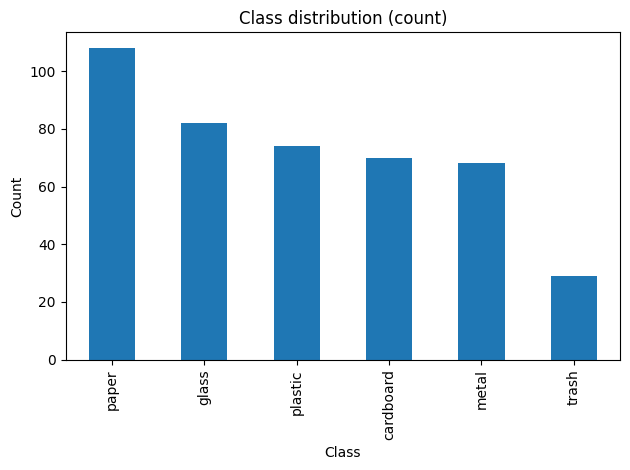

In [14]:
plt.figure()
stats["count"].plot(kind="bar")
plt.title("Class distribution (count)")
plt.xlabel("Class")
plt.ylabel("Count")
plt.tight_layout()
plt.show()


# Check missing files 

In [15]:
df["path"] = df["filename"].apply(lambda x: IMAGES_DIR / x)
missing = df[~df["path"].apply(lambda p: p.exists())]
print("\nMissing files:", len(missing))
if len(missing) > 0:
    print(missing.head(10))


Missing files: 431
           filename  label class_name  \
0       paper70.jpg      2      paper   
1      paper380.jpg      2      paper   
2   cardboard31.jpg      3  cardboard   
3       glass12.jpg      1      glass   
4      paper169.jpg      2      paper   
5  cardboard334.jpg      3  cardboard   
6      paper271.jpg      2      paper   
7      paper319.jpg      2      paper   
8      glass373.jpg      1      glass   
9    plastic125.jpg      4    plastic   

                                                path  
0  Garbage Classification/Garbage classification_...  
1  Garbage Classification/Garbage classification_...  
2  Garbage Classification/Garbage classification_...  
3  Garbage Classification/Garbage classification_...  
4  Garbage Classification/Garbage classification_...  
5  Garbage Classification/Garbage classification_...  
6  Garbage Classification/Garbage classification_...  
7  Garbage Classification/Garbage classification_...  
8  Garbage Classification/Garbage

# Visualize sample images per class

In [18]:
from pathlib import Path

IMAGES_ROOT = Path("Garbage classification_in/Garbage classification_inner").resolve()
print("IMAGES_ROOT:", IMAGES_ROOT)
print("exists:", IMAGES_ROOT.exists())

IMAGES_ROOT: /Users/volkanguner/Desktop/DSAI SON/Capstone Project/Garbage Classification/Garbage classification_in/Garbage classification_inner
exists: True


In [19]:
def build_path(row):
    fname = str(row["filename"])

    # If filename already contains a folder like "cardboard/xxx.jpg"
    p1 = IMAGES_ROOT / fname

    # Otherwise, join with class_name folder
    p2 = IMAGES_ROOT / str(row["class_name"]) / fname

    return str((p1 if p1.exists() else p2).resolve())

df["path"] = df.apply(build_path, axis=1)

In [20]:
missing = (~df["path"].apply(lambda p: Path(p).exists())).sum()
print("Missing paths:", missing)

print("Example:", df["path"].iloc[0])
print("Exists:", Path(df["path"].iloc[0]).exists())

Missing paths: 0
Example: /Users/volkanguner/Desktop/DSAI SON/Capstone Project/Garbage Classification/Garbage classification_in/Garbage classification_inner/paper/paper70.jpg
Exists: True


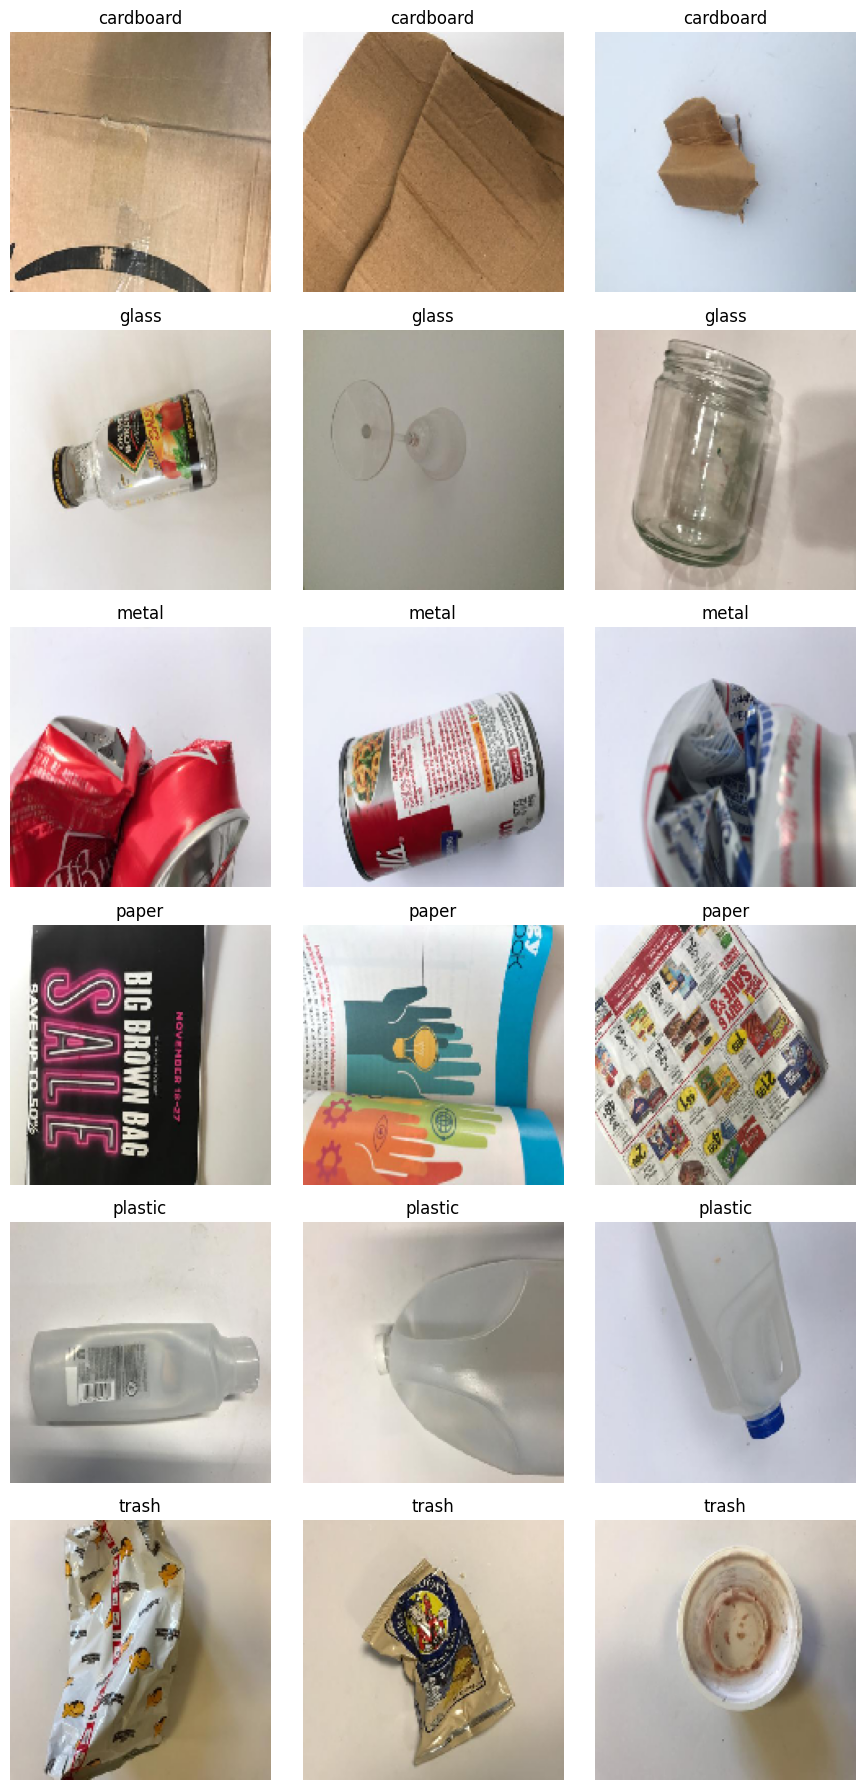

In [21]:
def show_samples(df, n_per_class=3, img_size=(160, 160)):
    classes = sorted(df["class_name"].unique())
    plt.figure(figsize=(3 * n_per_class, 3 * len(classes)))
    plot_i = 1
    for cls in classes:
        subset = df[df["class_name"] == cls].sample(min(n_per_class, (df["class_name"] == cls).sum()), random_state=SEED)
        for _, r in subset.iterrows():
            img = keras.utils.load_img(r["path"], target_size=img_size)
            ax = plt.subplot(len(classes), n_per_class, plot_i)
            plt.imshow(img)
            plt.title(cls)
            plt.axis("off")
            plot_i += 1
    plt.tight_layout()
    plt.show()

show_samples(df, n_per_class=3)

2) Preprocessing + Train/Val/Test split (and why)

# Train/Val/Test split

In [22]:
train_df, test_df = train_test_split(
    df, test_size=0.15, random_state=SEED, stratify=df["class_name"]
)
train_df, val_df = train_test_split(
    train_df, test_size=0.15, random_state=SEED, stratify=train_df["class_name"]
)

print("Train:", len(train_df), "Val:", len(val_df), "Test:", len(test_df))

Train: 311 Val: 55 Test: 65


# Label encoding

In [23]:
class_names = sorted(df["class_name"].unique())
class_to_idx = {c: i for i, c in enumerate(class_names)}
idx_to_class = {i: c for c, i in class_to_idx.items()}

train_df["y"] = train_df["class_name"].map(class_to_idx)
val_df["y"] = val_df["class_name"].map(class_to_idx)
test_df["y"] = test_df["class_name"].map(class_to_idx)

NUM_CLASSES = len(class_names)
print("Classes:", class_names)

Classes: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']


# tf.data pipeline

In [24]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, IMG_SIZE)
    img = tf.cast(img, tf.float32) / 255.0
    return img, label

def make_ds(df_in, training=False):
    paths = df_in["path"].astype(str).values
    labels = df_in["y"].values.astype(np.int32)
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    if training:
        ds = ds.shuffle(1000, seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    return ds

train_ds = make_ds(train_df, training=True)
val_ds = make_ds(val_df, training=False)
test_ds = make_ds(test_df, training=False)


2026-02-08 22:44:52.873577: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M1
2026-02-08 22:44:52.873855: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 8.00 GB
2026-02-08 22:44:52.873860: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 2.67 GB
2026-02-08 22:44:52.873913: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-02-08 22:44:52.874407: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


# Data augmentation layer

In [25]:
data_aug = keras.Sequential(
    [
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.05),
        layers.RandomZoom(0.1),
        layers.RandomContrast(0.1),
    ],
    name="data_augmentation",
)

3) Training details (hyperparameters + optimization)

# Class weights (handles imbalance)

In [26]:
from sklearn.utils.class_weight import compute_class_weight

cw = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(NUM_CLASSES),
    y=train_df["y"].values
)
class_weight = {i: float(w) for i, w in enumerate(cw)}
print("Class weights:", {idx_to_class[k]: round(v, 3) for k, v in class_weight.items()})


Class weights: {'cardboard': 1.037, 'glass': 0.864, 'metal': 1.058, 'paper': 0.665, 'plastic': 0.96, 'trash': 2.592}


# Model factory + training loop for comparisons

In [27]:
def build_model(backbone_name: str, lr=3e-4, weight_decay=1e-4, dropout=0.2):
    inputs = keras.Input(shape=(*IMG_SIZE, 3))
    x = data_aug(inputs)

    if backbone_name == "MobileNetV2":
        base = keras.applications.MobileNetV2(
            include_top=False, weights="imagenet", input_shape=(*IMG_SIZE, 3)
        )
        preprocess = keras.applications.mobilenet_v2.preprocess_input
    elif backbone_name == "EfficientNetB0":
        base = keras.applications.EfficientNetB0(
            include_top=False, weights="imagenet", input_shape=(*IMG_SIZE, 3)
        )
        preprocess = keras.applications.efficientnet.preprocess_input
    elif backbone_name == "ResNet50":
        base = keras.applications.ResNet50(
            include_top=False, weights="imagenet", input_shape=(*IMG_SIZE, 3)
        )
        preprocess = keras.applications.resnet.preprocess_input
    else:
        raise ValueError("Unknown backbone_name")

    base.trainable = False  # stage-1: feature extraction

    # Apply model-specific preprocessing
    x = layers.Lambda(lambda t: preprocess(t * 255.0))(x)

    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

    model = keras.Model(inputs, outputs, name=f"{backbone_name}_classifier")

    # AdamW = Adam + weight decay
    optimizer = keras.optimizers.AdamW(learning_rate=lr, weight_decay=weight_decay)
    model.compile(
        optimizer=optimizer,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model, base

# ====== 13) Training helpers ======
def plot_history(h, title):
    plt.figure()
    plt.plot(h.history["loss"], label="train_loss")
    plt.plot(h.history["val_loss"], label="val_loss")
    plt.title(title + " - Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.tight_layout()
    plt.show()

    plt.figure()
    plt.plot(h.history["accuracy"], label="train_acc")
    plt.plot(h.history["val_accuracy"], label="val_acc")
    plt.title(title + " - Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.tight_layout()
    plt.show()

def evaluate_model(model, test_ds, test_df):
    y_true = test_df["y"].values
    y_prob = model.predict(test_ds, verbose=0)
    y_pred = np.argmax(y_prob, axis=1)

    print(classification_report(y_true, y_pred, target_names=class_names))

    cm = confusion_matrix(y_true, y_pred)
    plt.figure()
    plt.imshow(cm)
    plt.title("Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.xticks(range(NUM_CLASSES), class_names, rotation=45, ha="right")
    plt.yticks(range(NUM_CLASSES), class_names)
    plt.colorbar()
    plt.tight_layout()
    plt.show()

    return {
        "test_accuracy": float((y_pred == y_true).mean()),
    }

# Run experiments + compare models


Training: MobileNetV2
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
Epoch 1/20


2026-02-08 22:45:10.616330: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


10/10 ━━━━━━━━━━━━━━━━━━━━ 14s 685ms/step - accuracy: 0.2111 - loss: 2.2460 - val_accuracy: 0.1636 - val_loss: 1.9569 - learning_rate: 3.0000e-04
Epoch 2/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 274ms/step - accuracy: 0.2864 - loss: 1.8414 - val_accuracy: 0.2545 - val_loss: 1.7999 - learning_rate: 3.0000e-04
Epoch 3/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 276ms/step - accuracy: 0.3221 - loss: 1.7469 - val_accuracy: 0.3636 - val_loss: 1.6586 - learning_rate: 3.0000e-04
Epoch 4/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 267ms/step - accuracy: 0.4580 - loss: 1.4803 - val_accuracy: 0.4000 - val_loss: 1.5085 - learning_rate: 3.0000e-04
Epoch 5/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 267ms/step - accuracy: 0.4815 - loss: 1.3361 - val_accuracy: 0.4727 - val_loss: 1.3990 - learning_rate: 3.0000e-04
Epoch 6/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 260ms/step - accuracy: 0.5077 - loss: 1.3004 - val_accuracy: 0.4909 - val_loss: 1.3280 - learning_rate: 3.0000e-04
Epoch 7/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 269ms/step - accuracy: 0.5808 - l

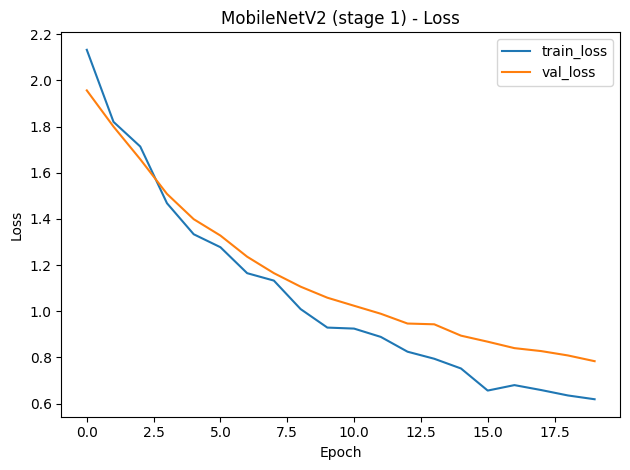

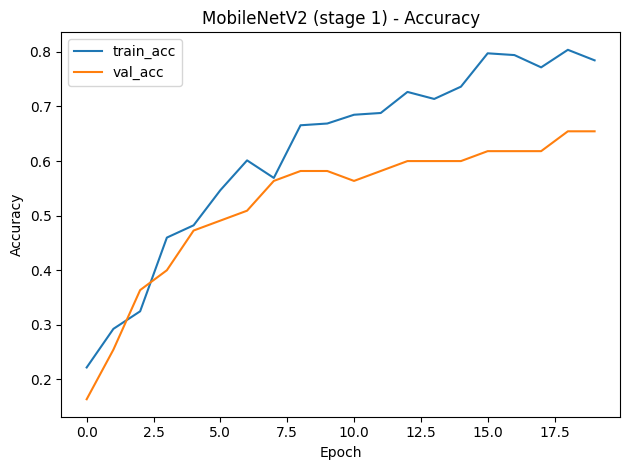

Epoch 1/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 18s 921ms/step - accuracy: 0.5731 - loss: 1.0030 - val_accuracy: 0.6545 - val_loss: 0.7725 - learning_rate: 1.0000e-05
Epoch 2/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 4s 368ms/step - accuracy: 0.6004 - loss: 0.9413 - val_accuracy: 0.6727 - val_loss: 0.7627 - learning_rate: 1.0000e-05
Epoch 3/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 4s 370ms/step - accuracy: 0.6686 - loss: 0.8763 - val_accuracy: 0.7091 - val_loss: 0.7529 - learning_rate: 1.0000e-05
Epoch 4/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 4s 353ms/step - accuracy: 0.7305 - loss: 0.7388 - val_accuracy: 0.7091 - val_loss: 0.7440 - learning_rate: 1.0000e-05
Epoch 5/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 4s 371ms/step - accuracy: 0.7335 - loss: 0.7138 - val_accuracy: 0.7091 - val_loss: 0.7348 - learning_rate: 1.0000e-05
Epoch 6/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 4s 342ms/step - accuracy: 0.6943 - loss: 0.6901 - val_accuracy: 0.7091 - val_loss: 0.7263 - learning_rate: 1.0000e-05
Epoch 7/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 4s 336ms/step - accuracy:

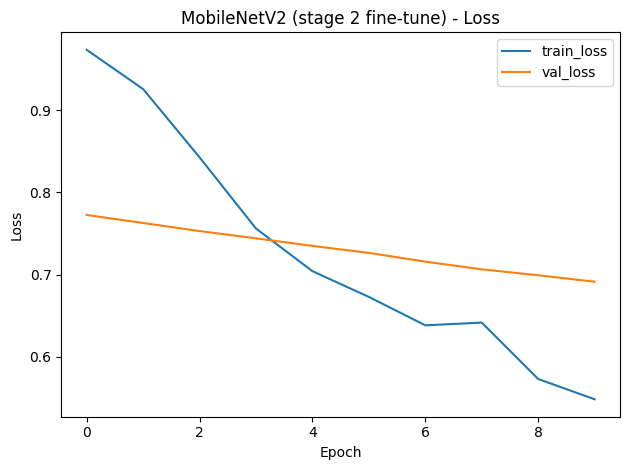

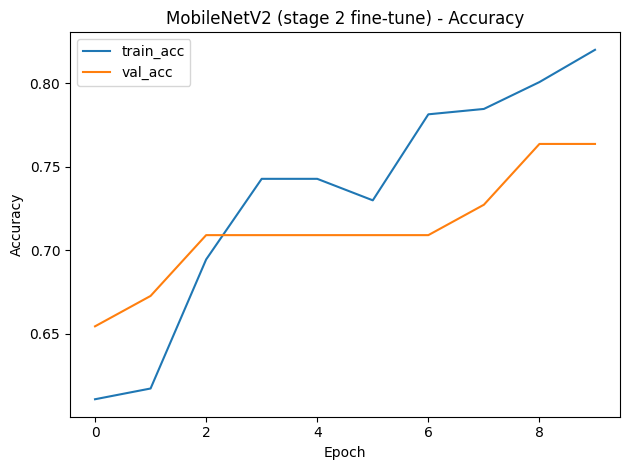

              precision    recall  f1-score   support

   cardboard       0.77      0.91      0.83        11
       glass       0.53      0.83      0.65        12
       metal       1.00      0.50      0.67        10
       paper       0.79      0.69      0.73        16
     plastic       0.82      0.82      0.82        11
       trash       0.67      0.40      0.50         5

    accuracy                           0.72        65
   macro avg       0.76      0.69      0.70        65
weighted avg       0.76      0.72      0.72        65



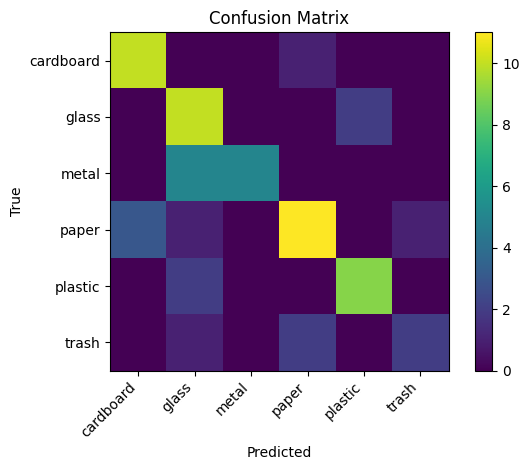


Training: EfficientNetB0
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 7s 0us/step
Epoch 1/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 19s 1s/step - accuracy: 0.2313 - loss: 1.7474 - val_accuracy: 0.3091 - val_loss: 1.6378 - learning_rate: 3.0000e-04
Epoch 2/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 5s 404ms/step - accuracy: 0.2838 - loss: 1.7242 - val_accuracy: 0.4364 - val_loss: 1.5011 - learning_rate: 3.0000e-04
Epoch 3/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 4s 387ms/step - accuracy: 0.4155 - loss: 1.5501 - val_accuracy: 0.4909 - val_loss: 1.3817 - learning_rate: 3.0000e-04
Epoch 4/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 4s 389ms/step - accuracy: 0.5362 - loss: 1.4296 - val_accuracy: 0.5818 - val_loss: 1.2755 - learning_rate: 3.0000e-04
Epoch 5/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 4s 373ms/step - accuracy: 0.5834 - loss: 1.3369 - val_accuracy: 0.6182 - val_loss: 1.1856 - learning_rate: 3.0000e-04
Epoch 6/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 4s 383ms/step - accuracy: 0.5927 - loss: 1.1850 - val_accuracy: 0.6182 - val_loss: 1.1082 - learning_rate: 

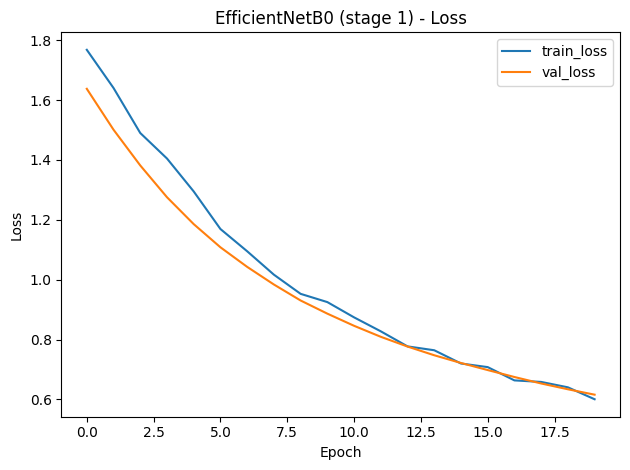

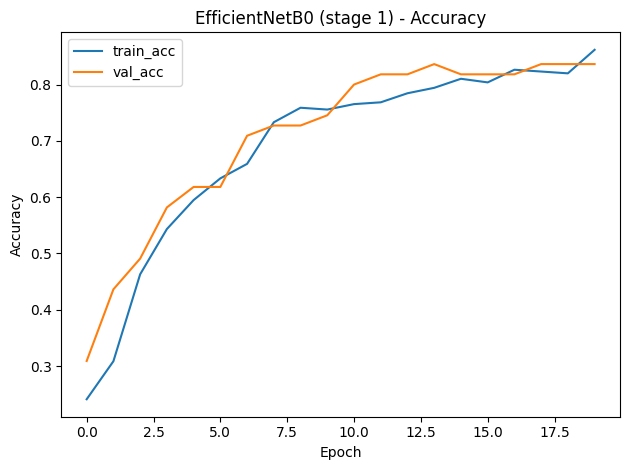

Epoch 1/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 37s 2s/step - accuracy: 0.7176 - loss: 0.9276 - val_accuracy: 0.8182 - val_loss: 0.6171 - learning_rate: 1.0000e-05
Epoch 2/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 18s 1s/step - accuracy: 0.7266 - loss: 0.9990 - val_accuracy: 0.8182 - val_loss: 0.6203 - learning_rate: 1.0000e-05
Epoch 3/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 14s 999ms/step - accuracy: 0.7333 - loss: 0.9458 - val_accuracy: 0.8364 - val_loss: 0.6238 - learning_rate: 1.0000e-05
Epoch 4/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 7s 620ms/step - accuracy: 0.7446 - loss: 0.9379 - val_accuracy: 0.8364 - val_loss: 0.6348 - learning_rate: 3.0000e-06
Epoch 5/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 6s 608ms/step - accuracy: 0.7800 - loss: 0.8897 - val_accuracy: 0.8364 - val_loss: 0.6464 - learning_rate: 3.0000e-06
Epoch 6/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 8s 823ms/step - accuracy: 0.7585 - loss: 0.9390 - val_accuracy: 0.8364 - val_loss: 0.6593 - learning_rate: 1.0000e-06


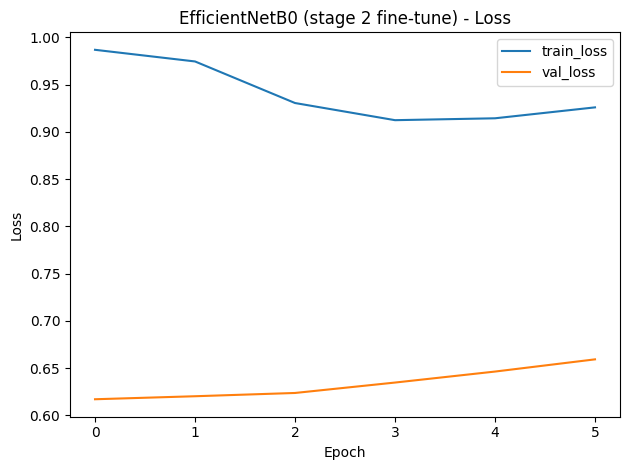

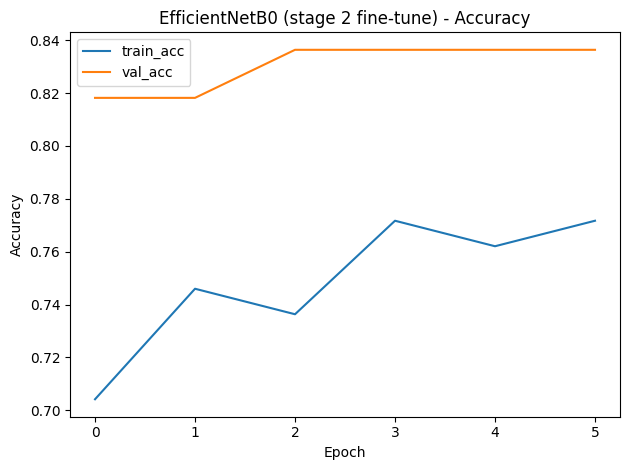

              precision    recall  f1-score   support

   cardboard       0.77      0.91      0.83        11
       glass       0.62      0.83      0.71        12
       metal       1.00      0.90      0.95        10
       paper       0.87      0.81      0.84        16
     plastic       0.70      0.64      0.67        11
       trash       1.00      0.40      0.57         5

    accuracy                           0.78        65
   macro avg       0.83      0.75      0.76        65
weighted avg       0.81      0.78      0.78        65



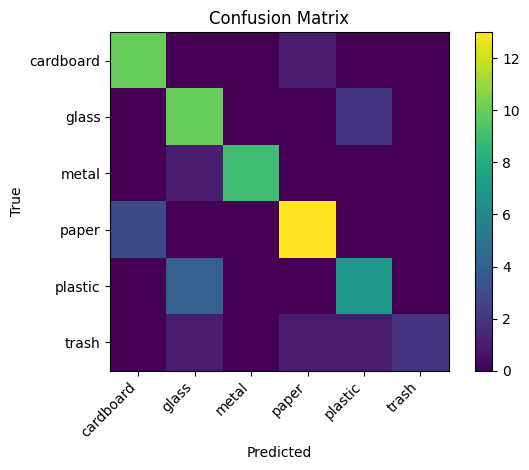


Training: ResNet50
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 26s 0us/step
Epoch 1/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 21s 1s/step - accuracy: 0.1573 - loss: 2.4747 - val_accuracy: 0.2000 - val_loss: 1.7287 - learning_rate: 3.0000e-04
Epoch 2/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 6s 583ms/step - accuracy: 0.2338 - loss: 1.8068 - val_accuracy: 0.4000 - val_loss: 1.4223 - learning_rate: 3.0000e-04
Epoch 3/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 5s 533ms/step - accuracy: 0.4040 - loss: 1.5174 - val_accuracy: 0.5636 - val_loss: 1.1811 - learning_rate: 3.0000e-04
Epoch 4/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 5s 512ms/step - accuracy: 0.4503 - loss: 1.3307 - val_accuracy: 0.6727 - val_loss: 1.0400 - learning_rate: 3.0000e-04
Epoch 5/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 5s 516ms/step - accuracy: 0.5946 - loss: 1.1146 - val_accuracy: 0.7273 - val_loss: 0.9236 - learning_rate: 3.0000e-04
Epoch 6/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 5s 502ms/step - accuracy: 0.5172 - loss: 1.0969 - val_accuracy: 0.7273 - val_loss: 0.8361 - learning_rate: 3.000

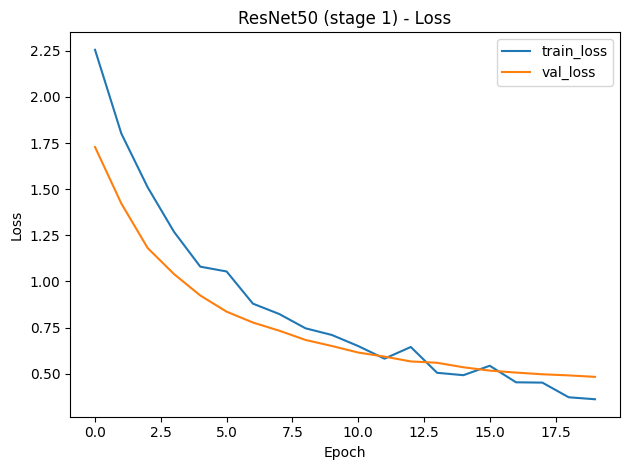

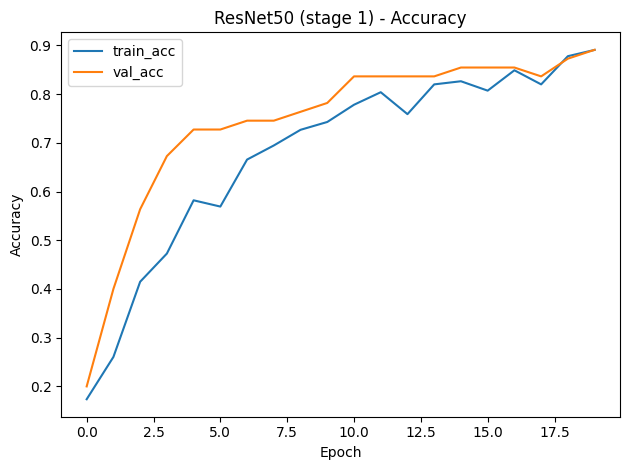

Epoch 1/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 39s 2s/step - accuracy: 0.6973 - loss: 0.6376 - val_accuracy: 0.8364 - val_loss: 0.4757 - learning_rate: 1.0000e-05
Epoch 2/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 14s 1s/step - accuracy: 0.7709 - loss: 0.5715 - val_accuracy: 0.8182 - val_loss: 0.4881 - learning_rate: 1.0000e-05
Epoch 3/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 10s 962ms/step - accuracy: 0.8458 - loss: 0.4172 - val_accuracy: 0.8182 - val_loss: 0.4993 - learning_rate: 1.0000e-05
Epoch 4/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 9s 859ms/step - accuracy: 0.9037 - loss: 0.3750 - val_accuracy: 0.8000 - val_loss: 0.4939 - learning_rate: 3.0000e-06
Epoch 5/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 8s 822ms/step - accuracy: 0.8798 - loss: 0.3822 - val_accuracy: 0.8000 - val_loss: 0.4902 - learning_rate: 3.0000e-06
Epoch 6/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 8s 809ms/step - accuracy: 0.8768 - loss: 0.3327 - val_accuracy: 0.8000 - val_loss: 0.4834 - learning_rate: 1.0000e-06


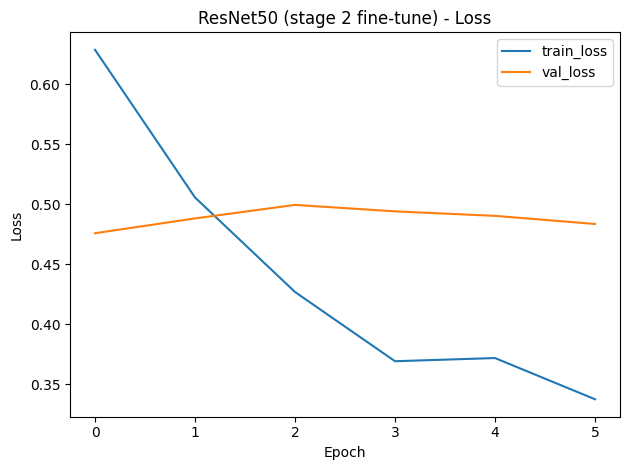

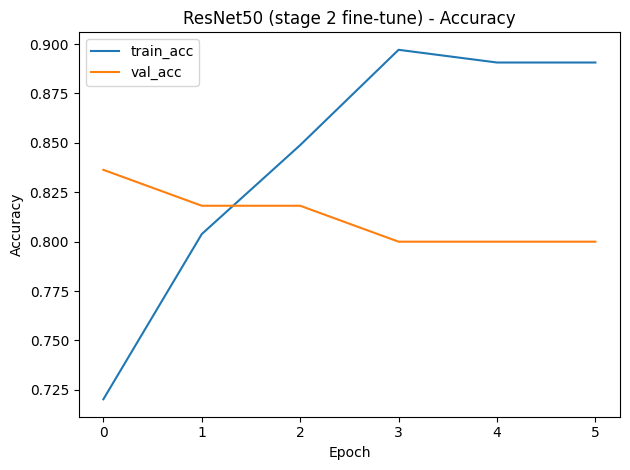

              precision    recall  f1-score   support

   cardboard       0.77      0.91      0.83        11
       glass       0.73      0.92      0.81        12
       metal       0.89      0.80      0.84        10
       paper       0.73      0.69      0.71        16
     plastic       0.80      0.73      0.76        11
       trash       0.67      0.40      0.50         5

    accuracy                           0.77        65
   macro avg       0.77      0.74      0.74        65
weighted avg       0.77      0.77      0.76        65



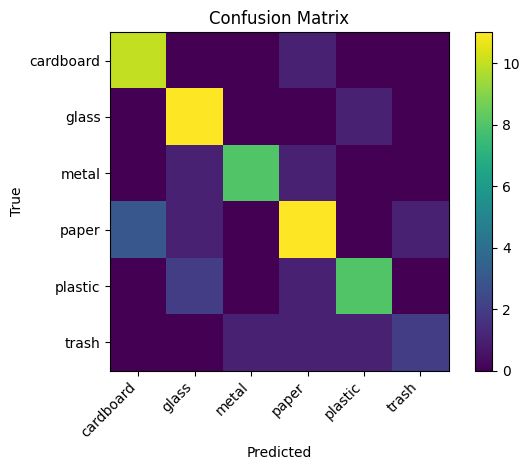


Model comparison:
             model  test_accuracy
1  EfficientNetB0       0.784615
2        ResNet50       0.769231
0     MobileNetV2       0.723077


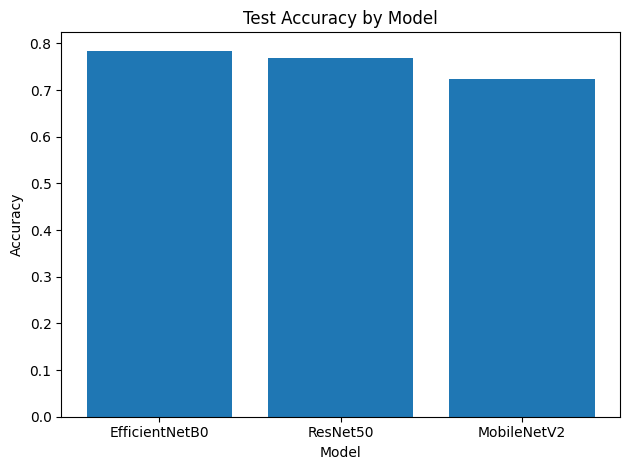

In [28]:
backbones = ["MobileNetV2", "EfficientNetB0", "ResNet50"]

results = []
histories = {}
saved_models = {}

for b in backbones:
    print("\n==============================")
    print("Training:", b)
    print("==============================")

    model, base = build_model(b, lr=3e-4, weight_decay=1e-4, dropout=0.25)

    callbacks = [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, min_lr=1e-6),
    ]

    # Stage 1: feature extraction
    h1 = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=20,
        class_weight=class_weight,
        callbacks=callbacks,
        verbose=1
    )

    plot_history(h1, f"{b} (stage 1)")

    # Stage 2: fine-tuning (unfreeze last ~20% of layers)
    base.trainable = True
    n = len(base.layers)
    for layer in base.layers[: int(n * 0.8)]:
        layer.trainable = False

    model.compile(
        optimizer=keras.optimizers.AdamW(learning_rate=1e-5, weight_decay=1e-4),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    h2 = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=10,
        class_weight=class_weight,
        callbacks=callbacks,
        verbose=1
    )

    plot_history(h2, f"{b} (stage 2 fine-tune)")

    # Evaluate
    metrics = evaluate_model(model, test_ds, test_df)
    results.append({"model": b, **metrics})

    histories[b] = (h1, h2)
    saved_models[b] = model

# Comparison table 
results_df = pd.DataFrame(results).sort_values("test_accuracy", ascending=False)
print("\nModel comparison:\n", results_df)

plt.figure()
plt.bar(results_df["model"], results_df["test_accuracy"])
plt.title("Test Accuracy by Model")
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.tight_layout()
plt.show()


5) “Garbage detector” inference tool (predict one image)

In [29]:
best_name = results_df.iloc[0]["model"]
best_model = saved_models[best_name]
print("Best model:", best_name)

def predict_image(image_path: str):
    image_path = str(image_path)
    img = keras.utils.load_img(image_path, target_size=IMG_SIZE)
    arr = keras.utils.img_to_array(img) / 255.0
    arr = np.expand_dims(arr, axis=0)

    probs = best_model.predict(arr, verbose=0)[0]
    pred_idx = int(np.argmax(probs))
    return {
        "predicted_class": idx_to_class[pred_idx],
        "confidence": float(probs[pred_idx]),
        "all_probs": {idx_to_class[i]: float(probs[i]) for i in range(NUM_CLASSES)}
    }

Best model: EfficientNetB0
